# 00 · Setup and download

**What this notebook does.** It prepares everything the other notebooks need:

1. records which Python and package versions are installed;
2. finds the GEO data (GSE298774) on disk, or downloads them from GEO if they are missing;
3. unpacks the GEO archive into one flat folder;
4. checks that the paper's supplementary tables are available;
5. makes an inventory of the unpacked files and lists which files exist for every tissue section.

**Why it matters.** Every later result depends on knowing exactly which files exist and where they are.
No analysis happens here.

| | |
|---|---|
| **Inputs** | Internet access to GEO, *or* an existing `GSE298774_RAW.tar`; the supplementary Excel file of the paper |
| **Outputs (data, not committed)** | `data/GSE298774/raw/*.gz`, series matrix (the tar is used where it already is, or downloaded to `data/GSE298774/`) |
| **Outputs (committed)** | `manifests/environment_versions.csv`, `manifests/inventory/*`, `manifests/file_presence.csv`, `figures/00_setup/file_presence.png` |

**Where the data go.** By default `multimodal-retrieval/data/GSE298774/` (ignored by git).
To use another folder, set the environment variable `SPACEMEL_DATA` *before* starting Jupyter, e.g. on Windows PowerShell
`$env:SPACEMEL_DATA = "C:\path\to\GSE298774"`. The supplementary files go to `data/supplementary/`
(or `SPACEMEL_SUPP`).

In [1]:
# --- Setup: make src/ importable, load helpers, define all paths -------------
import sys
from pathlib import Path
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacemel_io as sio
import spacemel_plots as splot

P = sio.get_paths()
sio.ensure_output_dirs(P)
FIG = P["figures"] / "00_setup"
FIG.mkdir(parents=True, exist_ok=True)
MAN = P["manifests"]
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 80)
print("repo      :", P["repo"])
print("raw data  :", P["raw"])
print("figures:", FIG)
print("manifests:", MAN)

repo      : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval
raw data  : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\data\GSE298774\raw
figures: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\figures\00_setup
manifests: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\manifests


## 0.1 · Software versions

The analysis was written for the versions pinned in `environment.yml`. This cell records what is actually installed,
so that results can be traced back to a software state.

In [2]:
import platform
from importlib.metadata import version, PackageNotFoundError
pkgs = ["numpy", "pandas", "scipy", "anndata", "scanpy", "matplotlib", "pillow", "openpyxl", "h5py"]
rows = [{"package": "python", "version": platform.python_version()}]
for name in pkgs:
    try:
        rows.append({"package": name, "version": version(name)})
    except PackageNotFoundError:
        rows.append({"package": name, "version": "NOT INSTALLED"})
versions = pd.DataFrame(rows)
versions.to_csv(MAN / "environment_versions.csv", index=False)
versions

,package,version
0,python,3.14.7
1,numpy,2.5.4
2,pandas,3.1.0
3,scipy,1.18.1
4,anndata,0.13.4
5,scanpy,1.12.4
6,matplotlib,3.11.2
7,pillow,11.3.0
8,openpyxl,3.1.5
9,h5py,3.16.0


## 0.2 · Get the data (local copy first, GEO download otherwise)

Two files are needed (source: the GEO series page of GSE298774):

* `GSE298774_series_matrix.txt.gz`: sample descriptions (titles, protocols), a few kB;
* `GSE298774_RAW.tar`: all Visium output files, about 1.4 GB.

The series matrix is downloaded into the data folder if it is missing. For the archive, the cell looks first in the
data folder, then in the places listed in `LOCAL_TAR_CANDIDATES` (edit the list if your copy is elsewhere), and uses
the first copy it finds **where it is** (no second copy is made). Only if none exists is it downloaded from GEO
(`DOWNLOAD_IF_MISSING = True`), with progress printed every 2 seconds. A download is written to `.part` and renamed only
when complete; an incomplete download raises an error. The size printed for each file in bytes is the check that it is
complete.

In [3]:
# 0.2 · Get the data: use an existing local copy if there is one, otherwise download from GEO
import time, urllib.request
from pathlib import Path

# Where you already have the archive (checked first, in this order). Edit if yours is elsewhere.
LOCAL_TAR_CANDIDATES = [
    P["repo"] / "data" / "GSE298774_RAW.tar",
    Path.home() / "Downloads" / "GSE298774" / "GSE298774_RAW.tar",
    Path.home() / "Downloads" / "GSE298774_RAW.tar",
]
DOWNLOAD_IF_MISSING = True

series_path = P["data"] / "GSE298774_series_matrix.txt.gz"
default_tar = P["data"] / "GSE298774_RAW.tar"

def download_with_progress(url, dest, chunk_mb=1, every_s=2.0):
    if dest.exists():
        print(f"already present: {dest} ({dest.stat().st_size:,} bytes)")
        return
    tmp = dest.with_suffix(dest.suffix + ".part")          # renamed only when complete
    req = urllib.request.Request(url, headers={"User-Agent": "spacemel-dc9-download"})
    with urllib.request.urlopen(req) as r, open(tmp, "wb") as f:
        total = int(r.headers.get("Content-Length") or 0)
        print(f"downloading {dest.name} ({total / 1e6:.0f} MB)" if total else f"downloading {dest.name}")
        done, t0, t_last = 0, time.time(), 0.0
        while buf := r.read(int(chunk_mb * 1024 * 1024)):
            f.write(buf)
            done += len(buf)
            if time.time() - t_last >= every_s:
                t_last = time.time()
                speed = done / (t_last - t0)
                line = f"  {done / 1e6:8.1f} MB"
                if total:
                    line += f" / {total / 1e6:.1f} MB ({100 * done / total:5.1f} %)  ~{(total - done) / speed / 60:4.1f} min left"
                print(line + f"  {speed / 1e6:4.1f} MB/s", end="\r", flush=True)
    if total and done != total:
        raise IOError(f"incomplete: {done:,} of {total:,} bytes - re-run this cell")
    tmp.replace(dest)
    print(f"\ndone: {dest.name} ({dest.stat().st_size:,} bytes) in {(time.time() - t0) / 60:.1f} min")

# 1) Series matrix (small): download if missing
download_with_progress(sio.SERIES_MATRIX_URL, series_path)

# 2) RAW tar: the data folder first, then your local copies, then (optionally) GEO
found = [p for p in [default_tar] + LOCAL_TAR_CANDIDATES if p.exists()]
if found:
    tar_path = found[0]
    print(f"using existing archive: {tar_path} ({tar_path.stat().st_size:,} bytes)")
elif DOWNLOAD_IF_MISSING:
    tar_path = default_tar
    download_with_progress(sio.RAW_TAR_URL, tar_path)
else:
    tar_path = default_tar
    print("RAW tar not found locally and DOWNLOAD_IF_MISSING = False")

leftover = default_tar.with_suffix(".tar.part")
if leftover.exists() and found:
    leftover.unlink()
    print("removed unfinished download:", leftover.name)

print("RAW tar present      :", tar_path.exists(), "|", tar_path)
print("series matrix present:", series_path.exists())

already present: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\data\GSE298774\GSE298774_series_matrix.txt.gz (3,298 bytes)
using existing archive: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\data\GSE298774_RAW.tar (1,402,705,920 bytes)
RAW tar present      : True | C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\data\GSE298774_RAW.tar
series matrix present: True


## 0.3 · Unpack the archive

`GSE298774_RAW.tar` contains a flat list of gzip-compressed files named `GSM<id>_<section>_<file>.gz`
(e.g. `GSM9022967_A24_tissue_positions.csv.gz`). They are copied, still compressed, into `data/GSE298774/raw/`.
The loaders read `.gz` files directly, so nothing is decompressed to disk.

In [4]:
if tar_path.exists():
    n_new = sio.extract_raw_tar(tar_path, P["raw"])
    print(f"newly extracted files: {n_new}")
print(f"files in {P['raw']}: {len(list(P['raw'].iterdir()))}")

newly extracted files: 0
files in C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\data\GSE298774\raw: 150


## 0.4 · Paper supplementary tables

Notebooks 01 and 04 read Supplementary Tables S1 (patients), S4 (differentially expressed genes) and S5
(on/off genes) from `can-25-2934_supplementary_tables_suppst1.xlsx`, downloaded from the article page
(doi:10.1158/0008-5472.CAN-25-2934, section "Supplementary Data"). Place it in the folder printed below.

In [5]:
print("expected at:", P["supp_tables"])
print("present    :", P["supp_tables"].exists())

expected at: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\data\supplementary\can-25-2934_supplementary_tables_suppst1.xlsx
present    : True


## 0.5 · Inventory of the unpacked files

For every file in `data/GSE298774/raw/` this step records, without changing anything: its size; for images, the size
in pixels; the scale factors; the matrix dimensions (genes × barcodes, non-zero entries; header only); the number of
lines of the barcode and feature files; the number of array positions and in-tissue spots; and the micrometres per
full-resolution pixel measured from the spot grid (neighbouring spots in a row are 100 µm apart).
From these, µm per pixel of the hires and aligned_fiducials images = µm per full-res pixel / scale factor.

Outputs: `manifests/inventory/inventory_files.csv` (one row per file) and `manifests/inventory/inventory_summary.csv`
(one row per section). The earlier script `scripts/00_inventory.py` (reads the tar directly) is kept as the record of
the first inventory but is not used here.

In [6]:
import gzip

def mtx_header(path):
    """Dimensions line of a Matrix Market file: genes, barcodes, non-zero entries (reads only the header)."""
    with gzip.open(path, "rt") as f:
        for line in f:
            if not line.startswith("%"):
                return [int(v) for v in line.split()]

def count_lines(path):
    with gzip.open(path, "rt") as f:
        return sum(1 for _ in f)

inv_dir = MAN / "inventory"
inv_dir.mkdir(parents=True, exist_ok=True)

files = sio.discover_files(P["raw"])
file_rows, summary = [], {}
for r in files[files.kind != "unrecognised"].itertuples():
    p = Path(r.path)
    info = {"gsm": r.gsm, "section": r.section_id, "kind": r.kind, "file": p.name, "size_bytes": p.stat().st_size}
    s = summary.setdefault((r.gsm, r.section_id), {"gsm": r.gsm, "section": r.section_id})
    if r.kind in ("hires_image", "lowres_image", "fiducials_image"):
        wh = list(sio.load_image(p).size)
        info["detail"] = f"{wh[0]} x {wh[1]} px"
        s[{"hires_image": "hires_wh", "lowres_image": "lowres_wh", "fiducials_image": "fiducials_wh"}[r.kind]] = wh
    elif r.kind == "scalefactors":
        sf = sio.load_scalefactors(p)
        info["detail"] = str(sf)
        s.update(hires_scalef=sf["tissue_hires_scalef"], lowres_scalef=sf["tissue_lowres_scalef"],
                 regist_target_img_scalef=sf.get("regist_target_img_scalef"),
                 spot_diameter_fullres=sf["spot_diameter_fullres"])
    elif r.kind == "positions":
        pos = sio.load_positions(p)
        um, _, _ = sio.grid_um_per_px(pos)
        info["detail"] = f"{len(pos)} positions, {int((pos.in_tissue == 1).sum())} in tissue"
        s.update(n_positions=len(pos), n_in_tissue=int((pos.in_tissue == 1).sum()), um_per_fullres_px=round(um, 4))
    elif r.kind == "matrix":
        dims = mtx_header(p)
        info["detail"] = f"{dims[0]} genes x {dims[1]} barcodes, {dims[2]} non-zero"
        s.update(mtx_genes=dims[0], mtx_barcodes=dims[1], mtx_nonzero=dims[2])
    elif r.kind in ("barcodes", "features"):
        n = count_lines(p)
        info["detail"] = f"{n} lines"
        s["n_barcodes" if r.kind == "barcodes" else "n_features"] = n
    file_rows.append(info)
    print(f"  read {p.name}")

inventory_files = pd.DataFrame(file_rows)
inventory = pd.DataFrame(summary.values())
inventory["um_per_hires_px"] = (inventory.um_per_fullres_px / inventory.hires_scalef).round(2)
inventory["spot55um_in_hires_px"] = (55 / inventory.um_per_hires_px).round(1)
inventory["um_per_fiducials_px"] = (inventory.um_per_fullres_px / inventory.regist_target_img_scalef).round(2)

inventory_files.to_csv(inv_dir / "inventory_files.csv", index=False)
inventory.to_csv(inv_dir / "inventory_summary.csv", index=False)
print(f"\n{len(inventory_files)} files, {len(inventory)} sections -> {inv_dir}")
inventory

  read GSM9022963_A17_aligned_fiducials.jpg.gz
  read GSM9022963_A17_barcodes.tsv.gz
  read GSM9022963_A17_features.tsv.gz
  read GSM9022963_A17_matrix.mtx.gz
  read GSM9022963_A17_scalefactors_json.json.gz
  read GSM9022963_A17_tissue_hires_image.png.gz
  read GSM9022963_A17_tissue_lowres_image.png.gz
  read GSM9022963_A17_tissue_positions.csv.gz
  read GSM9022963_A2_aligned_fiducials.jpg.gz
  read GSM9022963_A2_matrix.mtx.gz
  read GSM9022963_A2_scalefactors_json.json.gz
  read GSM9022963_A2_tissue_hires_image.png.gz
  read GSM9022963_A2_tissue_lowres_image.png.gz
  read GSM9022963_A2_tissue_positions.csv.gz
  read GSM9022964_A7_aligned_fiducials.jpg.gz
  read GSM9022964_A7_barcodes.tsv.gz
  read GSM9022964_A7_features.tsv.gz
  read GSM9022964_A7_matrix.mtx.gz
  read GSM9022964_A7_scalefactors_json.json.gz
  read GSM9022964_A7_tissue_hires_image.png.gz
  read GSM9022964_A7_tissue_lowres_image.png.gz
  read GSM9022964_A7_tissue_positions.csv.gz
  read GSM9022965_A21_aligned_fiducials.

,gsm,section,fiducials_wh,n_barcodes,n_features,mtx_genes,mtx_barcodes,mtx_nonzero,hires_scalef,lowres_scalef,regist_target_img_scalef,spot_diameter_fullres,hires_wh,lowres_wh,n_positions,n_in_tissue,um_per_fullres_px,um_per_hires_px,spot55um_in_hires_px,um_per_fiducials_px
0,GSM9022963,A17,"[3000, 3000]",13887.0,37082.0,37082,13887,3928455,0.033015,0.009905,0.099046,163.630909,"[2000, 1989]","[600, 597]",14336,2274,0.3663,11.09,5.0,3.70
1,GSM9022963,A2,"[3000, 3000]",NaN,NaN,37082,13916,3928455,0.033015,0.009905,0.099046,163.630909,"[2000, 1989]","[600, 597]",14336,3367,0.3663,11.09,5.0,3.70
2,GSM9022964,A7,"[3000, 3000]",4985.0,37082.0,37082,4985,4465510,0.042960,0.012888,0.128880,318.374339,"[1677, 2000]","[503, 600]",4992,2892,0.2198,5.12,10.7,1.71
3,GSM9022965,A21,"[3000, 3000]",2260.0,18085.0,18085,2260,6486295,0.037701,0.011310,0.113103,237.919077,"[2000, 1894]","[600, 568]",4992,2260,0.2941,7.80,7.1,2.60
4,GSM9022966,A16,"[3000, 3000]",5195.0,18085.0,18085,5195,11241079,0.031214,0.009364,0.093643,163.447121,"[2000, 1639]","[600, 492]",14336,5195,0.3676,11.78,4.7,3.93
5,GSM9022966,A23,"[3000, 3000]",2782.0,18085.0,18085,2782,7460306,0.031214,0.009364,0.093643,163.447121,"[2000, 1639]","[600, 492]",14336,2782,0.3676,11.78,4.7,3.93
6,GSM9022967,A22,"[3000, 3000]",14336.0,37082.0,37082,14336,50577269,0.034264,0.010279,0.102793,155.369556,"[2000, 1834]","[600, 550]",14336,4326,0.3861,11.27,4.9,3.76
7,GSM9022967,A24,"[3000, 3000]",14335.0,37082.0,37082,14335,50577269,0.034264,0.010279,0.102793,155.369556,"[2000, 1834]","[600, 550]",14336,6165,0.3861,11.27,4.9,3.76
8,GSM9022968,A34,"[3000, 3000]",14203.0,37082.0,37082,14203,3515417,0.031742,0.009523,0.095226,212.233402,"[2000, 1391]","[600, 417]",14336,4151,0.2825,8.90,6.2,2.97
9,GSM9022969,B1,"[3000, 3000]",14328.0,37082.0,37082,14328,40712398,0.037086,0.011126,0.111257,185.193732,"[2000, 1934]","[600, 580]",14336,3952,0.3236,8.73,6.3,2.91


## 0.6 · Which files exist for which tissue section

Each GEO file name is parsed into *GSM* (capture area), *section* (patient tissue piece) and *file kind*.
The table and figure show which of the 8 expected file kinds are present for each section. A section can only be
loaded if it has positions, scale factors, matrix, barcodes and features.

In [7]:
# Uses the tables made in 0.5: `files` (every file in raw/, incl. unrecognised) and `inventory_files`
print("unrecognised files:", files.loc[files.kind == "unrecognised", "path"].tolist())

presence = (inventory_files.assign(present=1)
            .pivot_table(index=["gsm", "section"], columns="kind", values="present", fill_value=0)
            .astype(int))
presence.to_csv(MAN / "file_presence.csv")
presence

unrecognised files: []


kind                barcodes  features  fiducials_image  hires_image  lowres_image  matrix  positions  scalefactors
gsm        section                                                                                                 
GSM9022963 A17             1         1                1            1             1       1          1             1
           A2              0         0                1            1             1       1          1             1
GSM9022964 A7              1         1                1            1             1       1          1             1
GSM9022965 A21             1         1                1            1             1       1          1             1
GSM9022966 A16             1         1                1            1             1       1          1             1
           A23             1         1                1            1             1       1          1             1
GSM9022967 A22             1         1                1            1             1       1          1             1
           A24             1         1                1            1             1       1          1             1
GSM9022968 A34             1         1                1            1             1       1          1             1
GSM9022969 B1              1         1                1            1             1       1          1             1
           B38ex           1         1                1            1             1       1          1             1
GSM9022970 B4              1         1                1            1             1       1          1             1
GSM9022971 B13             1         1                1            1             1       1          1             1
           B8              1         1                1            1             1       1          1             1
GSM9022972 B14             1         1                1            1             1       1          1             1
           B15             1         1                1            1             1       1          1             1
           B38_2           1         1                1            1             1       1          1             1
GSM9022973 D20             1         1                1            1             1       1          1             1
           D3              1         1                1            1             1       1          1             1

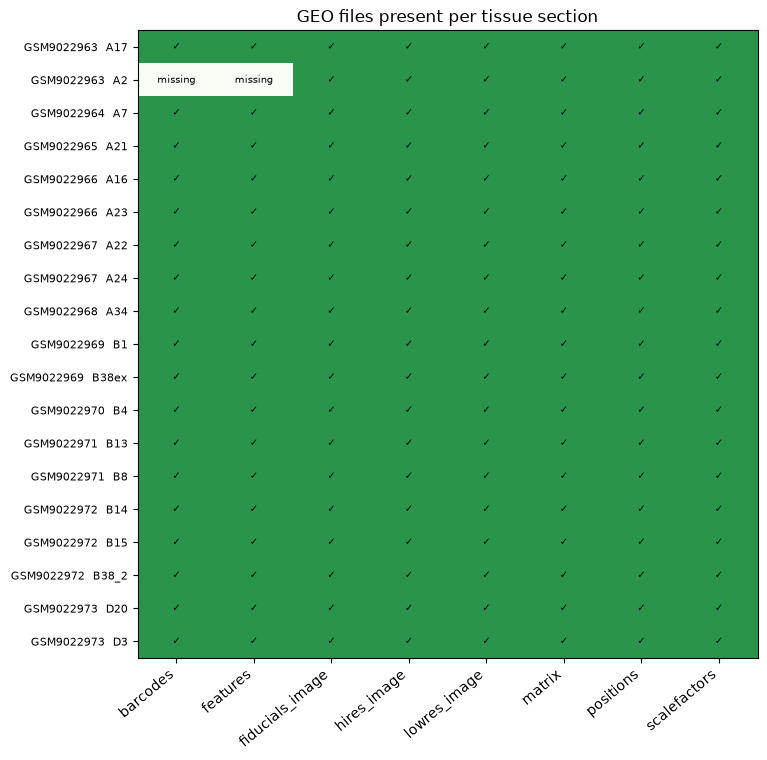

In [8]:
fig, ax = plt.subplots(figsize=(8, 0.35 * len(presence) + 1.5))
ax.imshow(presence.values, cmap="Greens", vmin=0, vmax=1.4, aspect="auto")
ax.set_xticks(range(presence.shape[1]))
ax.set_xticklabels(presence.columns, rotation=40, ha="right")
ax.set_yticks(range(presence.shape[0]))
ax.set_yticklabels([f"{g}  {s}" for g, s in presence.index], fontsize=8)
for i in range(presence.shape[0]):
    for j in range(presence.shape[1]):
        ax.text(j, i, "✓" if presence.values[i, j] else "missing", ha="center", va="center", fontsize=7)
ax.set_title("GEO files present per tissue section")
splot.savefig(fig, FIG / "file_presence.png")
plt.show()

## 0.7 · Observations

*From the outputs of this run (8 Nov 2026).*

* **Files (0.5–0.6).** 150 files, 19 sections on 11 GSMs, no unrecognised file names. All sections have all 8 file kinds
  except **A2, which has no `barcodes` and no `features` file**.
* **Array sizes.** 4,992 positions (6.5 mm) for A7, A21, D3, D20; 14,336 positions (11 mm) for all other sections.
* **Gene panels.** 18,085 features for A16, A21, A23; 37,082 for the other sections with a features file
  (A2's matrix also has 37,082 rows).
* **Matrix scope.** For A16, A21 and A23 the number of matrix barcodes equals the number of in-tissue spots
  (5,195; 2,260; 2,782). For all other sections the matrix has more barcodes than in-tissue spots
  (e.g. A24: 14,335 barcodes, 6,165 in tissue). Sections sharing a whole-array matrix on the same GSM have the same
  number of non-zero entries (A16 and A23, whose matrices are section-only, differ: 11,241,079 vs 7,460,306);
  A22 and A24 differ by one barcode column (14,336 vs 14,335) with identical non-zero counts (50,577,269).
  A2's matrix has 13,916 columns, A17's 13,887, both with 3,928,455 non-zero entries.
* **Scale factors** are identical for all sections of the same GSM.
* **Pixel sizes.** Full-resolution: 0.2198–0.3861 µm/px. hires image: 5.12–11.78 µm/px, so one 55 µm spot is
  4.7–10.7 hires pixels. aligned_fiducials.jpg: 1.71–3.93 µm/px **if** its scale factor applies to the spot
  coordinates (tested in notebook 03).